In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [3]:
data = pd.read_csv('datasets/archive/AAPL.csv')
data.shape #(rows, columns)

(11082, 8)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11082 entries, 0 to 11081
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          11082 non-null  object 
 1   Open          11082 non-null  float64
 2   High          11082 non-null  float64
 3   Low           11082 non-null  float64
 4   Close         11082 non-null  float64
 5   Volume        11082 non-null  int64  
 6   Dividends     11082 non-null  float64
 7   Stock Splits  11082 non-null  float64
dtypes: float64(6), int64(1), object(1)
memory usage: 692.8+ KB


In [7]:
data.head(10)

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,1980-12-12 00:00:00-05:00,0.098834,0.099264,0.098834,0.098834,469033600,0.0,0.0
1,1980-12-15 00:00:00-05:00,0.094108,0.094108,0.093678,0.093678,175884800,0.0,0.0
2,1980-12-16 00:00:00-05:00,0.087232,0.087232,0.086802,0.086802,105728000,0.0,0.0
3,1980-12-17 00:00:00-05:00,0.088951,0.089381,0.088951,0.088951,86441600,0.0,0.0
4,1980-12-18 00:00:00-05:00,0.091530,0.091959,0.091530,0.091530,73449600,0.0,0.0
5,1980-12-19 00:00:00-05:00,0.097116,0.097545,0.097116,0.097116,48630400,0.0,0.0
6,1980-12-22 00:00:00-05:00,0.101842,0.102273,0.101842,0.101842,37363200,0.0,0.0
7,1980-12-23 00:00:00-05:00,0.106140,0.106570,0.106140,0.106140,46950400,0.0,0.0
8,1980-12-24 00:00:00-05:00,0.111726,0.112156,0.111726,0.111726,48003200,0.0,0.0
9,1980-12-26 00:00:00-05:00,0.122039,0.122469,0.122039,0.122039,55574400,0.0,0.0


In [24]:
data.dtypes

Date             object
Open            float64
High            float64
Low             float64
Close           float64
Volume            int64
Dividends       float64
Stock Splits    float64
dtype: object

In [25]:
data.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,11082.000000,11082.000000,11082.000000,11082.000000,1.108200e+04,11082.000000,11082.000000
mean,22.999465,23.245089,22.765351,23.016211,3.160454e+08,0.000792,0.001534
std,48.624006,49.135626,48.147580,48.668007,3.350015e+08,0.012178,0.083346
min,0.038245,0.038245,0.037815,0.037815,0.000000e+00,0.000000,0.000000
25%,0.242789,0.248055,0.237743,0.242844,1.116802e+08,0.000000,0.000000
50%,0.441069,0.449738,0.433847,0.441014,2.040030e+08,0.000000,0.000000
75%,18.006522,18.116080,17.709846,17.926857,3.970008e+08,0.000000,0.000000
max,235.947003,237.229001,234.192340,236.220108,7.421641e+09,0.250000,7.000000


In [8]:
data.isnull().sum()

Date            0
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

In [9]:
data.isna().sum()

Date            0
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

In [10]:
data.duplicated().sum() # number of duplicate rows

np.int64(0)

In [6]:
data['Date'] = pd.to_datetime(data['Date'], utc=True)

Text(0.5, 0, 'Opening Price')

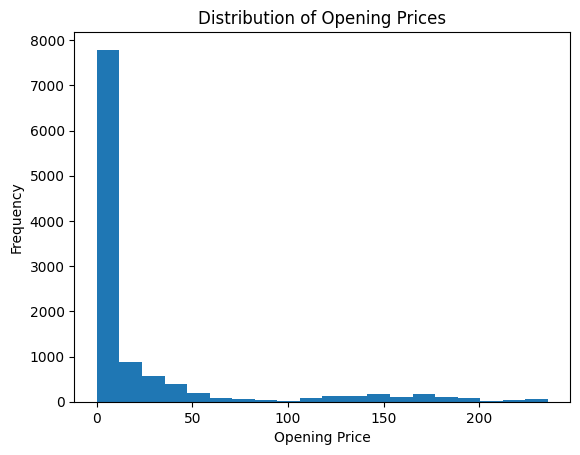

In [12]:
data['Open'].plot(kind='hist', 
                  bins=20, 
                  title="Distribution of Opening Prices")

plt.xlabel("Opening Price")

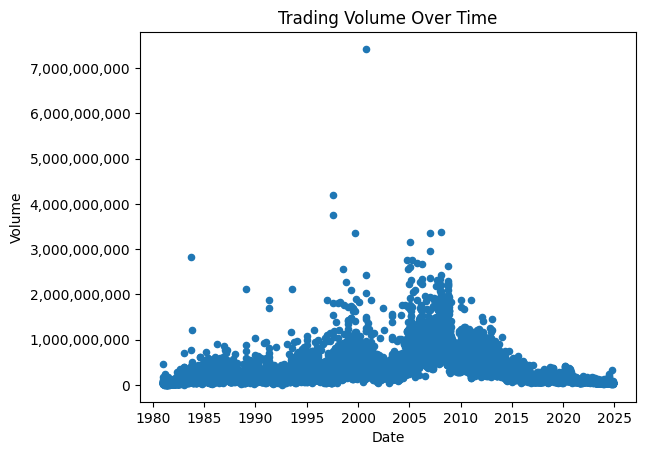

In [13]:
data.plot(kind='scatter', 
          x='Date', 
          y='Volume')

# Format the y-axis to avoid scientific notation
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

plt.title("Trading Volume Over Time")
plt.show()

<Axes: >

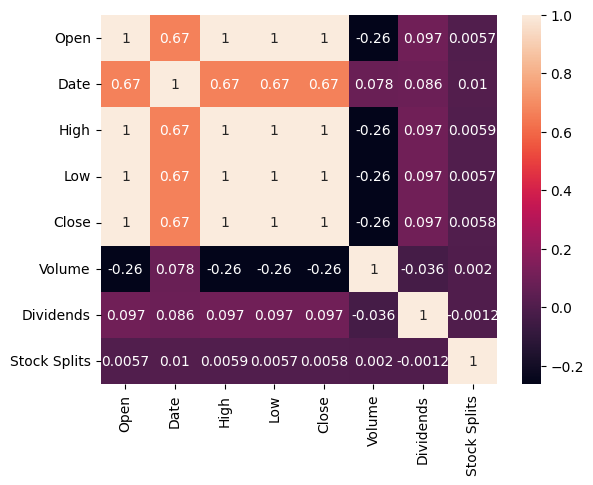

In [14]:
data_corr = data[['Open', 'Date', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits']].corr()

sns.heatmap(data_corr, annot=True)

Addition of CPI (Consumer Price Index) data 

- The CPI is retrieved monthly

In [15]:
import requests

api_key = 'ZIVQ43B8OGXYF6LT'

url = f'https://www.alphavantage.co/query?function=CPI&interval=monthly&apikey={api_key}'
r = requests.get(url)
cpi_data = r.json()

# Extract CPI values
cpi_monthly = cpi_data.get('data', [])

# Create a mapping from Year-Month to CPI value
cpi_mapping = {
    entry['date'][:7]: float(entry['value'])  # Extract Year-Month from the "date" field
    for entry in cpi_monthly
}

data['YearMonth'] = data['Date'].dt.strftime('%Y-%m')  # Extract Year-Month as a string

# Add CPI column to the dataset
data['CPI'] = data['YearMonth'].map(cpi_mapping)  # Map the CPI values

data.drop(columns=['YearMonth'], inplace=True)

data.head()



,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,CPI
0,1980-12-12 05:00:00+00:00,0.098834,0.099264,0.098834,0.098834,469033600,0.0,0.0,86.3
1,1980-12-15 05:00:00+00:00,0.094108,0.094108,0.093678,0.093678,175884800,0.0,0.0,86.3
2,1980-12-16 05:00:00+00:00,0.087232,0.087232,0.086802,0.086802,105728000,0.0,0.0,86.3
3,1980-12-17 05:00:00+00:00,0.088951,0.089381,0.088951,0.088951,86441600,0.0,0.0,86.3
4,1980-12-18 05:00:00+00:00,0.091530,0.091959,0.091530,0.091530,73449600,0.0,0.0,86.3


Calculating Features about data 

In [16]:
# Assigning a quarter based on the month in the 'Date' column
data['Quarter'] = data['Date'].dt.quarter

data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,CPI,Quarter
0,1980-12-12 05:00:00+00:00,0.098834,0.099264,0.098834,0.098834,469033600,0.0,0.0,86.3,4
1,1980-12-15 05:00:00+00:00,0.094108,0.094108,0.093678,0.093678,175884800,0.0,0.0,86.3,4
2,1980-12-16 05:00:00+00:00,0.087232,0.087232,0.086802,0.086802,105728000,0.0,0.0,86.3,4
3,1980-12-17 05:00:00+00:00,0.088951,0.089381,0.088951,0.088951,86441600,0.0,0.0,86.3,4
4,1980-12-18 05:00:00+00:00,0.091530,0.091959,0.091530,0.091530,73449600,0.0,0.0,86.3,4


In [17]:
data['Week_number'] = data['Date'].dt.isocalendar().week
data['Week_day'] = data['Date'].dt.weekday
data['Month']  = data['Date'].dt.month

data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,CPI,Quarter,Week_number,Week_day,Month
0,1980-12-12 05:00:00+00:00,0.098834,0.099264,0.098834,0.098834,469033600,0.0,0.0,86.3,4,50,4,12
1,1980-12-15 05:00:00+00:00,0.094108,0.094108,0.093678,0.093678,175884800,0.0,0.0,86.3,4,51,0,12
2,1980-12-16 05:00:00+00:00,0.087232,0.087232,0.086802,0.086802,105728000,0.0,0.0,86.3,4,51,1,12
3,1980-12-17 05:00:00+00:00,0.088951,0.089381,0.088951,0.088951,86441600,0.0,0.0,86.3,4,51,2,12
4,1980-12-18 05:00:00+00:00,0.091530,0.091959,0.091530,0.091530,73449600,0.0,0.0,86.3,4,51,3,12


Calculating Features on price 

In [18]:
#### Price Based Features #####

# Daily Range
data["Daily Range"] = data["High"] - data["Low"]

# Candle Size
data["Candle Size"] = (data["Close"] - data["Open"]).abs()

# 3. Direction
data["Direction"] = (data["Close"] > data["Open"]).astype(int)

# 4. Percentage Change
data["Percentage Change"] = ((data["Close"] - data["Open"]) / data["Open"]) * 100

# 5. Log Returns
data["Log Return"] = np.log(data["Close"] / data["Close"].shift(1))

# 6. Momentum (10-day)
data["Momentum_10"] = data["Close"] - data["Close"].shift(10)


# ===================== TREND AND MOVING AVERAGES =====================

# Simple Moving Average (SMA)
data["SMA_5"] = data["Close"].rolling(window=5).mean()
data["SMA_20"] = data["Close"].rolling(window=20).mean()

# Exponential Moving Average (EMA)
data["EMA_5"] = data["Close"].ewm(span=5, adjust=False).mean()
data["EMA_20"] = data["Close"].ewm(span=20, adjust=False).mean()


# ===================== VOLATILITY FEATURES =====================

# Rolling Standard Deviation (Volatility)
data["5-Day Volatility"] = data["Close"].rolling(window=5).std()


# Average True Range (ATR)
#data['TR'] = data[['High', 'Low', 'Close']].apply(
#    lambda row: max(row['High'] - row['Low'], 
#                    abs(row['High'] - row['Close'].shift(1)), 
#                    abs(row['Low'] - row['Close'].shift(1))) if not pd.isnull(row['Close'].shift(1)) else row['High'] - row['Low'], axis=1)
#data["ATR"] = data["TR"].rolling(window=14).mean()


# Bollinger Bands
data['Bollinger_SMA_20'] = data['Close'].rolling(window=20).mean()
data['Bollinger_Upper Band'] = data['Bollinger_SMA_20'] + (2 * data['Close'].rolling(window=20).std())
data['Bollinger_Lower Band'] = data['Bollinger_SMA_20'] - (2 * data['Close'].rolling(window=20).std())



# ===================== MOMENTUM AND OSCILLATORS =====================

# Relative Strength Index (RSI)
data['Change'] = data['Close'] - data['Close'].shift(1)
data['Gain'] = data['Change'].where(data['Change'] > 0, 0)
data['Loss'] = -data['Change'].where(data['Change'] < 0, 0)
data['Avg_Gain'] = data['Gain'].rolling(window=14).mean()
data['Avg_Loss'] = data['Loss'].rolling(window=14).mean()
data['RS'] = data['Avg_Gain'] / data['Avg_Loss']
data['RSI'] = 100 - (100 / (1 + data['RS']))



# Rate of Change (ROC)
data['ROC_10'] = ((data['Close'] - data['Close'].shift(10)) / data['Close'].shift(10)) * 100

# ===================== VOLUME-BASED FEATURES =====================

# Volume Moving Average
data['Volume_SMA_10'] = data['Volume'].rolling(window=10).mean()

# Volume Change (Percentage)
data['Volume Change'] = data['Volume'].pct_change() * 100

# On-Balance Volume (OBV)
data['OBV'] = (data['Volume'] * ((data['Close'] > data['Close'].shift(1)).astype(int) - (data['Close'] < data['Close'].shift(1)).astype(int))).cumsum()

# ===================== RETURN-BASED FEATURES =====================

# Daily Return
data['Daily Return'] = data['Close'].pct_change()

# Cumulative Return
data['Cumulative Return'] = (1 + data['Daily Return']).cumprod() - 1

# ===================== STATISTICAL FEATURES =====================

# Z-Score Normalization
data['Z-Score'] = (data['Close'] - data['Close'].rolling(window=20).mean()) / data['Close'].rolling(window=20).std()

# Skewness
data['Rolling Skewness'] = data['Close'].rolling(window=20).skew()

# Kurtosis
data['Rolling Kurtosis'] = data['Close'].rolling(window=20).kurt()

In [19]:
# 2. Calculate returns over different periods
data['7-Day Return'] = (data['Close'] / data['Close'].shift(7) - 1) * 100  # 7 days
data['1-Month Return'] = (data['Close'] / data['Close'].shift(30) - 1) * 100  # 30 days
data['6-Month Return'] = (data['Close'] / data['Close'].shift(182) - 1) * 100  # ~6 months
data['1-Year Return'] = (data['Close'] / data['Close'].shift(365) - 1) * 100  # 1 year

# 3. Calculate total return (all-time return from the first date)
data['Total Return'] = (data['Close'] / data['Close'].iloc[0] - 1) * 100

In [ ]:
row_1000 = data.iloc[1000]
row_1000

Date                    1984-11-26 05:00:00+00:00
Open                                     0.082506
High                                     0.082506
Low                                      0.082506
Close                                    0.082506
Volume                                  100643200
Dividends                                     0.0
Stock Splits                                  0.0
CPI                                         105.3
Quarter                                         4
Week_number                                    48
Week_day                                        0
Month                                          11
Daily Range                                   0.0
Candle Size                                   0.0
Direction                                       0
Percentage Change                             0.0
Log Return                               0.010471
Momentum_10                              0.002578
SMA_5                                    0.079326
